# Решение задачи кредитного скоринга 
Решение задачи кредитного скоринга будет представлено в нескольких ноутбуках. В данном ноутбуке будет проведен тюнинг модели.

## Данные
Датасет соревнования устроен таким образом, что кредиты для тренировочной выборки взяты за период в М месяцев, а кредиты для тестовой выборки взяты за последующие K месяцев.

Каждая запись кредитной истории содержит самую разнообразную информацию о прошлом кредите клиента, например, сумму, отношение клиента к кредиту, дату открытия и закрытия, информацию о просрочках по платежам и др. Все публикуемые данные тщательно анонимизированы.

Целевая переменная – бинарная величина, принимающая значения 0 и 1, где 1 соответствует дефолту клиента по кредиту.

## Проверка решения
Итоговая метрика решения - ROC AUC. Решения принимаются в виде csv-файла с двумя колонками: “id” – уникальный идентификатор и “score” – предсказание дефолта клиента по кредиту.

## Импорт библиотек

In [1]:
# Импорт библиотек
import json
import sys
import time

sys.path.append('../src')

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import loguniform, randint, uniform
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import ParameterSampler
from xgboost import XGBClassifier

from credit_scoring.validation import time_split

RANDOM_STATE = 13

## Чтение датасета
Прочитаем сагрегированный датасет и признаки, отобранные в ноутбуке grad_boost, и разобьём заявки по времени на train / valid / oot - так же, как в grad_boost.

In [2]:
# Чтение датасета и отобранных признаков
FEATURES = list(pd.read_csv('../artifacts/features.csv', index_col=0)['feature'])
data = pd.read_parquet('../artifacts/aggregated_df.parquet', columns=FEATURES + ['flag'])
data[FEATURES] = data[FEATURES].astype('float32')

train_df, valid_df, oot_df = time_split(data)
del data
X_train, y_train = train_df[FEATURES], train_df['flag']
X_valid, y_valid = valid_df[FEATURES], valid_df['flag']
X_oot, y_oot = oot_df[FEATURES], oot_df['flag']
print(f"Признаков: {len(FEATURES)}, train: {len(X_train):,}, valid: {len(X_valid):,}, oot: {len(X_oot):,}")

Признаков: 130, train: 1,800,000, valid: 600,000, oot: 600,000


## Baseline
Зафиксируем baseline - модель с параметрами по умолчанию на отобранных признаках. С ней будем сравнивать результат тюнинга.

In [3]:
# Baseline модель
baseline = XGBClassifier(tree_method='hist', random_state=RANDOM_STATE)
baseline.fit(X_train, y_train)
baseline_valid_auc = roc_auc_score(y_valid, baseline.predict_proba(X_valid)[:, 1])
print(f"Baseline valid ROC-AUC: {baseline_valid_auc:.4f}")

Baseline valid ROC-AUC: 0.7481


## Тюнинг модели градиентного бустинга
Тюнинг проведём в два этапа:
1. **Случайный поиск** параметров деревьев и регуляризации с фиксированным `learning_rate = 0.1`. Количество деревьев не перебираем: его подбирает early stopping по valid. Для скорости обучаем на случайной половине train, оцениваем на полном valid.
2. **Финальное обучение** лучших параметров на полном train с меньшим `learning_rate`: меньший шаг обычно немного улучшает качество, а количество деревьев снова подбирает early stopping.

Early stopping использует valid, поэтому valid ROC-AUC после тюнинга слегка оптимистичен. Честную оценку даст oot, который в подборе не участвует.

**Про флаг `RUN_SEARCH`.** Первый полный поиск (30 наборов, ~50 минут на прежних 70 признаках) показал очень плоскую поверхность качества: все наборы дали valid ROC-AUC 0.719-0.723, топ-10 укладывались в 0.0007. Основной вклад давали меньший `learning_rate` и количество деревьев. Поэтому после обновления признаков поиск по умолчанию не повторяем (`RUN_SEARCH = False`): берём прежние параметры деревьев из `artifacts/best_params.json` и заново подбираем только количество деревьев через early stopping. Чтобы повторить полный поиск, достаточно поставить `RUN_SEARCH = True`.

In [4]:
# Повторять ли случайный поиск параметров деревьев
RUN_SEARCH = False

In [5]:
# Пространство поиска
param_distributions = {
    'max_depth': randint(3, 9),
    'min_child_weight': loguniform(1, 300),
    'subsample': uniform(0.6, 0.4),
    'colsample_bytree': uniform(0.4, 0.6),
    'reg_lambda': loguniform(0.1, 100),
    'reg_alpha': loguniform(1e-3, 10),
}
N_ITER = 30

def make_model(learning_rate, **params):
    """XGBoost с early stopping по ROC-AUC на valid."""
    return XGBClassifier(
        tree_method='hist',
        learning_rate=learning_rate,
        n_estimators=5000,
        early_stopping_rounds=100,
        eval_metric='auc',
        random_state=RANDOM_STATE,
        **params,
    )

In [6]:
# Случайный поиск на половине train (или прежние параметры деревьев, если RUN_SEARCH = False)
if RUN_SEARCH:
    search_idx = X_train.sample(frac=0.5, random_state=RANDOM_STATE).index
    X_search, y_search = X_train.loc[search_idx], y_train.loc[search_idx]

    rows = []
    for i, params in enumerate(ParameterSampler(param_distributions, n_iter=N_ITER, random_state=RANDOM_STATE)):
        params = {k: (v.item() if hasattr(v, 'item') else v) for k, v in params.items()}
        start = time.time()
        model = make_model(0.1, **params)
        model.fit(X_search, y_search, eval_set=[(X_valid, y_valid)], verbose=False)
        rows.append({**params, 'n_trees': model.best_iteration + 1, 'valid_roc_auc': model.best_score, 'time_s': round(time.time() - start)})
        print(f"{i + 1:2d}/{N_ITER}: valid ROC-AUC = {model.best_score:.4f}, деревьев = {model.best_iteration + 1}")

    search_df = pd.DataFrame(rows).sort_values('valid_roc_auc', ascending=False).reset_index(drop=True)
    best_search_params = search_df.loc[0, list(param_distributions)].to_dict()
    best_search_params['max_depth'] = int(best_search_params['max_depth'])
    display(search_df.head(10))

    # Как параметры связаны с качеством
    fig, axes = plt.subplots(1, 6, figsize=(20, 3.5), sharey=True)
    for ax, p in zip(axes, param_distributions):
        ax.scatter(search_df[p], search_df['valid_roc_auc'])
        ax.set_title(p)
        if p in ('min_child_weight', 'reg_lambda', 'reg_alpha'):
            ax.set_xscale('log')
    axes[0].set_ylabel('Valid ROC-AUC')
    plt.tight_layout()
    plt.show()
else:
    with open('../artifacts/best_params.json', 'r', encoding='utf-8') as f:
        best_search_params = {k: v for k, v in json.load(f).items() if k in param_distributions}
    print("Поиск пропущен, используем прежние параметры деревьев:")
    print(best_search_params)

Поиск пропущен, используем прежние параметры деревьев:
{'max_depth': 5, 'min_child_weight': 1.6028310982259062, 'subsample': 0.8813688233629731, 'colsample_bytree': 0.7488629804880247, 'reg_lambda': 10.49660026127523, 'reg_alpha': 3.0004452380967637}


Поиск в этом прогоне пропущен (`RUN_SEARCH = False`), используются параметры деревьев из первого полного поиска: `max_depth = 5`, умеренная L2 (`reg_lambda` ~ 10) и заметная L1 (`reg_alpha` ~ 3) регуляризация. Поверхность качества в том поиске была очень плоской (все 30 наборов в пределах 0.719-0.723), поэтому заново подбираем только количество деревьев через early stopping.

### Финальное обучение
Обучим параметры деревьев на полном train с `learning_rate = 0.03`.

In [7]:
# Параметры деревьев - на полном train с меньшим learning_rate
FINAL_LR = 0.03

start = time.time()
tuned = make_model(FINAL_LR, **best_search_params)
tuned.fit(X_train, y_train, eval_set=[(X_valid, y_valid)], verbose=False)
print(f"Деревьев: {tuned.best_iteration + 1}, valid ROC-AUC: {tuned.best_score:.4f}, время: {time.time() - start:.0f} s")

Деревьев: 2149, valid ROC-AUC: 0.7560, время: 531 s


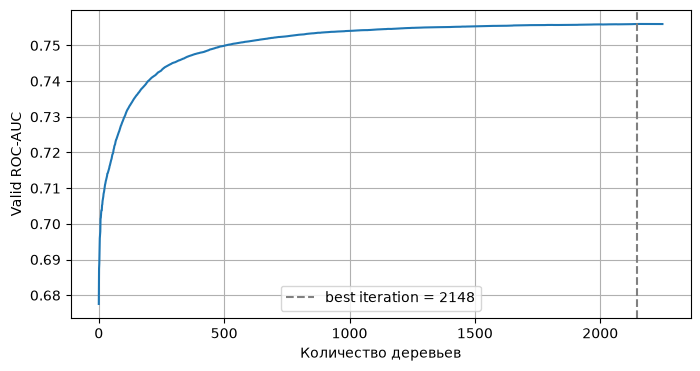

In [8]:
# Кривая обучения: ROC-AUC на valid по числу деревьев
valid_curve = tuned.evals_result()['validation_0']['auc']
plt.figure(figsize=(8, 4))
plt.plot(valid_curve)
plt.axvline(tuned.best_iteration, linestyle='--', color='gray', label=f'best iteration = {tuned.best_iteration}')
plt.xlabel('Количество деревьев')
plt.ylabel('Valid ROC-AUC')
plt.legend()
plt.grid(True)
plt.show()

## Оценка на out-of-time
Сравним baseline и модель после тюнинга на oot - заявках, которые не участвовали ни в обучении, ни в подборе параметров.

In [9]:
# Сравнение baseline и tuned на valid и oot
pd.DataFrame({
    'baseline': {
        'valid_roc_auc': baseline_valid_auc,
        'oot_roc_auc': roc_auc_score(y_oot, baseline.predict_proba(X_oot)[:, 1]),
    },
    'tuned': {
        'valid_roc_auc': roc_auc_score(y_valid, tuned.predict_proba(X_valid)[:, 1]),
        'oot_roc_auc': roc_auc_score(y_oot, tuned.predict_proba(X_oot)[:, 1]),
    },
}).T

,valid_roc_auc,oot_roc_auc
baseline,0.748137,0.735345
tuned,0.756025,0.744142


Выводы:
- финальное обучение с `learning_rate = 0.03` и early stopping дало прирост около +0.008-0.009 ROC-AUC и на valid (0.748 → 0.756), и на oot (0.735 → 0.744). Прирост на oot такой же, как на valid, значит модель не переобучилась под valid при early stopping;
- прирост почти совпадает с тем, что тюнинг давал на прежних признаках (+0.009): основной вклад даёт меньший шаг обучения с большим числом деревьев, а не конкретные параметры деревьев;
- модель тяжёлая: 2149 деревьев, обучение на полном train занимает несколько минут. Если обучение станет узким местом, `learning_rate = 0.05-0.1` даст почти то же качество в разы быстрее.

## Сохранение
Сохраним параметры итоговой модели. Количество деревьев фиксируем по early stopping, чтобы следующие ноутбуки могли обучать модель без valid.

In [10]:
# Сохраним параметры итоговой модели
best_params = {**best_search_params, 'learning_rate': FINAL_LR, 'n_estimators': int(tuned.best_iteration + 1)}
with open('../artifacts/best_params.json', 'w', encoding='utf-8') as f:
    json.dump(best_params, f, ensure_ascii=False, indent=4)
best_params

{'max_depth': 5,
 'min_child_weight': 1.6028310982259062,
 'subsample': 0.8813688233629731,
 'colsample_bytree': 0.7488629804880247,
 'reg_lambda': 10.49660026127523,
 'reg_alpha': 3.0004452380967637,
 'learning_rate': 0.03,
 'n_estimators': 2149}

## Итоги
1. Параметры деревьев взяты из первого полного поиска (поверхность качества плоская), количество деревьев заново подобрано early stopping по valid на новых признаках.
2. Честный результат на oot: ROC-AUC **0.744** против 0.735 у baseline на тех же признаках (на прежних признаках после тюнинга было 0.713).
3. Параметры итоговой модели (включая `learning_rate = 0.03` и `n_estimators = 2149`) сохранены в `artifacts/best_params.json`.

Далее - калибровка и выбор порогов на той же схеме валидации.